# RNA – Projeto Prático 2.1: Aprendizado Supervisionado no Neurônio Perceptron
Equipe com identificador **0** (arquivos `data020262.txt`, semente = 0).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from prettytable import PrettyTable
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from neuron import PerceptronNeuron

ID_EQUIPE = 0

def carregar(caminho):
    d = np.load(caminho, allow_pickle=True).reshape(-1, 3)
    return d[:, :2], d[:, 2].astype(int)

## Parte I – Problema linearmente separável (`dataAll20262.txt`)
Ativação degrau (ϑ = 0), η = 0,1, pesos ~ U(−0,5; 0,5), treino até a convergência.

Exemplos: 1000
Vetor inicial de pesos [w0, w1, w2]: [ 0.05632216 -0.35575962  0.47884499]


Vetor final de pesos   [w0, w1, w2]: [-4.36778359e-02  8.61123929e+01 -4.25480030e+02]
(a) Número total de ajustes no vetor de pesos: 65
(b) Número de épocas até a convergência:       4


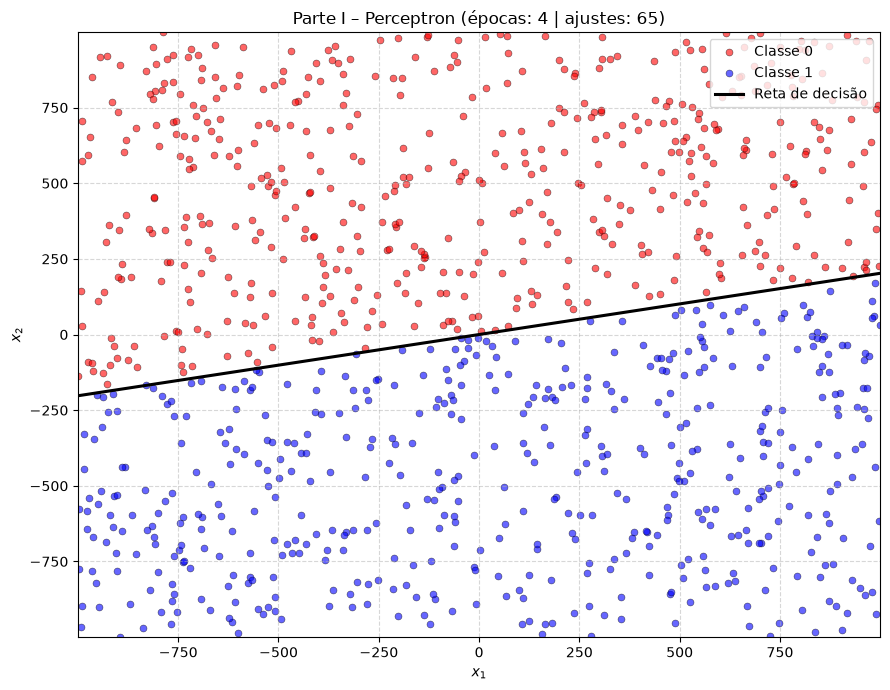

In [2]:
X, y = carregar("dados/dataAll20262.txt")
print("Exemplos:", X.shape[0])
p1 = PerceptronNeuron(learning_rate=0.1, limiar=0.0, weight_range=(-0.5, 0.5))
p1.train(X, y)
p1.plot_decision_boundary(X, y, title=f"Parte I – Perceptron (épocas: {p1.epochs} | ajustes: {p1.total_adjustments})")

## Parte II – Experimentação (`data{ID}20262.txt`)
6 configurações (η × intervalo dos pesos), 10 repetições cada.

In [3]:
X2, y2 = carregar(f"dados/data{ID_EQUIPE}20262.txt")
etas = [0.4, 0.1, 0.01]
intervalos = [(-100, 100), (-0.5, 0.5)]
N_REP = 10
# Nos dados desta equipe a convergência exige centenas de milhares de épocas (margem pequena).
MAX_EPOCAS = None  # treina até a convergência (rápido graças ao kernel Numba em neuron.py)
rng = np.random.default_rng(ID_EQUIPE)

tabela = PrettyTable(["Taxa de Aprendizado", "Intervalo de Pesos", "Qtde Ajustes (média ± dp)", "Min Épocas", "Max Épocas", "Convergiram"])
resultados = {}
for eta in etas:
    for inter in intervalos:
        ajustes, epocas, conv = [], [], []
        for _ in range(N_REP):
            n = PerceptronNeuron(learning_rate=eta, limiar=0.0, weight_range=inter)
            n.train(X2, y2, max_epochs=MAX_EPOCAS, rng=rng, verbose=False)
            ajustes.append(n.total_adjustments)
            epocas.append(n.epochs)
            conv.append(bool(np.all(n.predict(X2) == y2)))
        resultados[(eta, inter)] = (np.array(ajustes), np.array(epocas))
        tabela.add_row([f"η = {eta}", f"({inter[0]}, {inter[1]})",
                        f"{np.mean(ajustes):.2f} ± {np.std(ajustes):.2f}", min(epocas), max(epocas), f"{sum(conv)}/{N_REP}"])
print(tabela)

+---------------------+--------------------+---------------------------+------------+------------+-------------+
| Taxa de Aprendizado | Intervalo de Pesos | Qtde Ajustes (média ± dp) | Min Épocas | Max Épocas | Convergiram |
+---------------------+--------------------+---------------------------+------------+------------+-------------+
|       η = 0.4       |    (-100, 100)     |    2813128.90 ± 3611.36   |   239828   |   241613   |    10/10    |
|       η = 0.4       |    (-0.5, 0.5)     |    2811470.70 ± 3147.74   |   239581   |   241625   |    10/10    |
|       η = 0.1       |    (-100, 100)     |    2809699.50 ± 3526.40   |   239634   |   241435   |    10/10    |
|       η = 0.1       |    (-0.5, 0.5)     |    2809532.60 ± 2225.41   |   239688   |   240772   |    10/10    |
|       η = 0.01      |    (-100, 100)     |    2810007.20 ± 6571.25   |   239524   |   241636   |    10/10    |
|       η = 0.01      |    (-0.5, 0.5)     |    2809600.80 ± 3524.13   |   239414   |   241378  

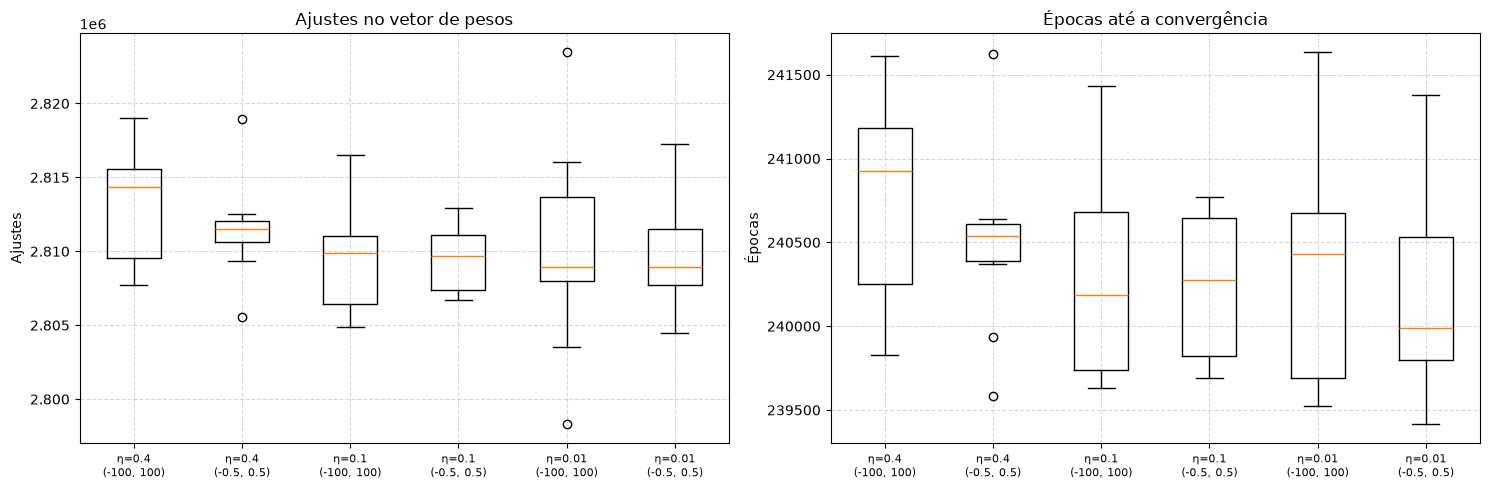

In [4]:
rotulos = [f"η={e}\n{i}" for (e, i) in resultados]
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
axs[0].boxplot([r[0] for r in resultados.values()], tick_labels=rotulos)
axs[0].set_title("Ajustes no vetor de pesos"); axs[0].set_ylabel("Ajustes")
axs[1].boxplot([r[1] for r in resultados.values()], tick_labels=rotulos)
axs[1].set_title("Épocas até a convergência"); axs[1].set_ylabel("Épocas")
for a in axs: a.grid(True, linestyle="--", alpha=0.5); a.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

### Análise
Nas 60 execuções (6 configurações × 10 repetições) todas convergiram, com cerca de 2,81 milhões de ajustes e entre 239 mil e 242 mil épocas. As médias e os desvios-padrão são praticamente idênticos entre as configurações e os boxplots se sobrepõem por completo.

**Não há evidência de uma configuração melhor ou pior: as seis são equivalentes** para estes dados. Explicações:
- A regra do Perceptron é homogênea: o degrau só depende do sinal de w·x, e cada ajuste soma η·e·x. Com η maior, o vetor w apenas cresce em escala; a fronteira de decisão é a mesma e o número de erros não muda.
- Os dados estão na escala de ±1000 e a margem entre as classes é pequena. Os pesos iniciais (mesmo em (−100, +100)) são desprezíveis diante da magnitude dos ajustes acumulados ao longo de milhões de atualizações, então o intervalo de inicialização também não afeta o resultado.
- O fator determinante é a geometria dos dados (margem pequena em relação ao raio da nuvem), que explica o número elevado de épocas em todas as configurações.